# How the strategy behaves in a race

Totals and averages tell us whether the strategy makes money. This notebook shows **how** it does it, by following the final strategy (γ = 0.5, green-up threshold 1, no diming) through a few races, one runner at a time.

Each race gets two charts that share a time axis, running from 350 s before the off (when we start quoting) to the off:

- **Prices.** Everything is shown as an implied probability of winning, so higher means shorter odds.
  - The grey band is the market's best bid and ask (the best backers' and layers' prices).
  - The thin grey line inside it is the mid.
  - The blue and orange lines are our own bid (our back) and ask (our lay).
  - Dots are our fills, and small grey crosses are trades between other people.
  - The shaded strip at the end is after $T$ = 30 s before the off, when we stop quoting and flatten our position.
- **Position.** Our position on that runner, in contracts: positive after we back it, negative after we lay it. A contract pays $1 if the runner wins.

The races are drawn at random from **15 February to 31 December**: every race after the validation days (1–14 February), so none of them was used to tune the strategy.

In [1]:
import importlib.util
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

# Project root = the folder that holds data/ (works whether this runs from evaluation/ or the root)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
sys.path.insert(0, str(ROOT))
from backtest.context import MarketStatus, MarketType, Side
from backtest.datasources import StreamMarketSource
from backtest.engine import Engine
from backtest.execution import QueueExecutionModel
from backtest.ledger import Ledger
from backtest.staking import FlatStake
from data.streamloaders import load_stream

# The final strategy (its file name has a hyphen, so it's loaded from the path)
spec = importlib.util.spec_from_file_location("final_strategy", ROOT / "strategies" / "_final-strategy.py")
final_strategy = importlib.util.module_from_spec(spec)
spec.loader.exec_module(final_strategy)

PROCESSED = ROOT / "data" / "processed" / "market_stream"
RACE_NUMBERS = json.loads((PROCESSED / "race_no_lookup.json").read_text())
MONTHS = ["Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
FIRST_DAY = 15                     # in February: 1-14 February were the validation days
N_RACES = 4                        # how many races to show
MIN_FILLS = 4                      # only show a race if one runner has at least this many of our quote fills
WINDOW = 400                       # replay the last 400 s before the off, as the backtests do
COMMISSION, LATENCY = 0.04, 0.2    # the same as the backtests
rng = np.random.default_rng(7)

# Chart style: blue = our back (bid), orange = our lay (ask), greys for the market
BLUE, ORANGE = "#2a78d6", "#eb6834"
GREY, LIGHT, SPREAD = "#898781", "#c3c2b7", "#e9e8e2"
INK, INK_2 = "#0b0b0b", "#52514e"
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2, "axes.labelpad": 6,
    "xtick.color": LIGHT, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "ytick.major.size": 0,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": LIGHT, "axes.linewidth": 0.8,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "lines.markersize": 7, "lines.markeredgewidth": 1.5, "lines.markeredgecolor": "white",
    "legend.frameon": False, "legend.fontsize": 9.5,
})


def titles(ax, title, subtitle, gap=10):
    # A bold headline, then a smaller line saying what is plotted (both kept out of the layout)
    note = ax.annotate(subtitle, (0, 1), xycoords="axes fraction", xytext=(0, gap), textcoords="offset points",
                       fontsize=9.5, color=INK_2, va="bottom", linespacing=1.45)
    head = ax.set_title(title, loc="left", fontsize=12.5, fontweight="semibold",
                        pad=gap + 6 + 14 * (subtitle.count("\n") + 1))
    note.set_in_layout(False)
    head.set_in_layout(False)

## Step 1: Replaying a race

We replay a race through the same backtest engine as the full runs (0.2 s latency, the engine's queue rules, 4% commission). The strategy doesn't keep a record of where its quotes sat, so we run it with a small recorder attached. After every book update, the recorder notes our current back and lay price on each runner. It changes nothing about how the strategy trades.

In [2]:
class RecordedStrategy(final_strategy.ASGMStrategy):
    # The final strategy, plus a log of our quoted prices after every book update
    def on_market_open(self, ctx):
        super().on_market_open(ctx)
        self.quote_log = []

    def on_snapshot(self, ctx):
        actions = super().on_snapshot(ctx)
        quoting = ctx.status is MarketStatus.OPEN and self.greenup_seconds < ctx.seconds_to_off <= self.start_seconds
        for r in ctx.runners:
            back, lay = self._quotes.get((r.selection_id, Side.BACK)), self._quotes.get((r.selection_id, Side.LAY))
            self.quote_log.append((ctx.seconds_to_off, r.selection_id,
                                   back.price if quoting and back else np.nan, lay.price if quoting and lay else np.nan))
        return actions


class OneRace:
    # The smallest possible data source: a single race
    def __init__(self, replay):
        self.replay = replay

    def markets(self):
        yield self.replay


def replay_race(path):
    # Run the final strategy on one race and return everything the charts need (None if it can't be replayed)
    df = load_stream(path)
    if df.empty:
        return None
    df = df[df["publish_time"] >= df["market_time"].min() - pd.Timedelta(seconds=WINDOW)]
    if df.empty:
        return None
    replay = StreamMarketSource(pattern=str(path), race_no_lookup=RACE_NUMBERS,
                                market_type_filter={MarketType.WIN})._build_replay(df)
    if replay is None or not replay.contexts:
        return None
    strategy, ledger = RecordedStrategy(), Ledger(commission_rate=COMMISSION)
    Engine(OneRace(replay), strategy, QueueExecutionModel(latency=LATENCY, ladder_depth=3), ledger, FlatStake(1.0),
           starting_bankroll=1000.0).run()
    return {"replay": replay, "strategy": strategy, "ledger": ledger}

## Step 2: Choosing the races

We shuffle every race from 15 February to 31 December with a fixed seed and replay them in that order. We keep the first four where one runner had at least four of our quotes filled: a race with only one or two fills doesn't show much. On each race we follow the runner with the most fills.

In [3]:
files = sorted(f for month in MONTHS for f in PROCESSED.joinpath(month).glob("*/*/*.parquet")
               if month != "Feb" or int(f.parent.parent.name) >= FIRST_DAY)   # files live in <month>/<day>/...
chosen, tried = [], 0
for i in rng.permutation(len(files)):
    tried += 1
    run = replay_race(files[i])
    if run is None or not run["strategy"].fill_log:
        continue
    fills = pd.DataFrame(run["strategy"].fill_log)
    quote_fills = fills[fills["tag"] == "quote"].groupby("selection_id").size()
    if quote_fills.empty or quote_fills.max() < MIN_FILLS:
        continue
    run["runner"] = quote_fills.idxmax()
    chosen.append(run)
    if len(chosen) == N_RACES:
        break
print(f"{len(files):,} races from 15 Feb to 31 Dec. Replayed {tried} of them, in random order, to find {len(chosen)} with at least {MIN_FILLS} fills on one runner")

41,666 races from 15 Feb to 31 Dec. Replayed 6 of them, in random order, to find 4 with at least 4 fills on one runner


## Step 3: The charts

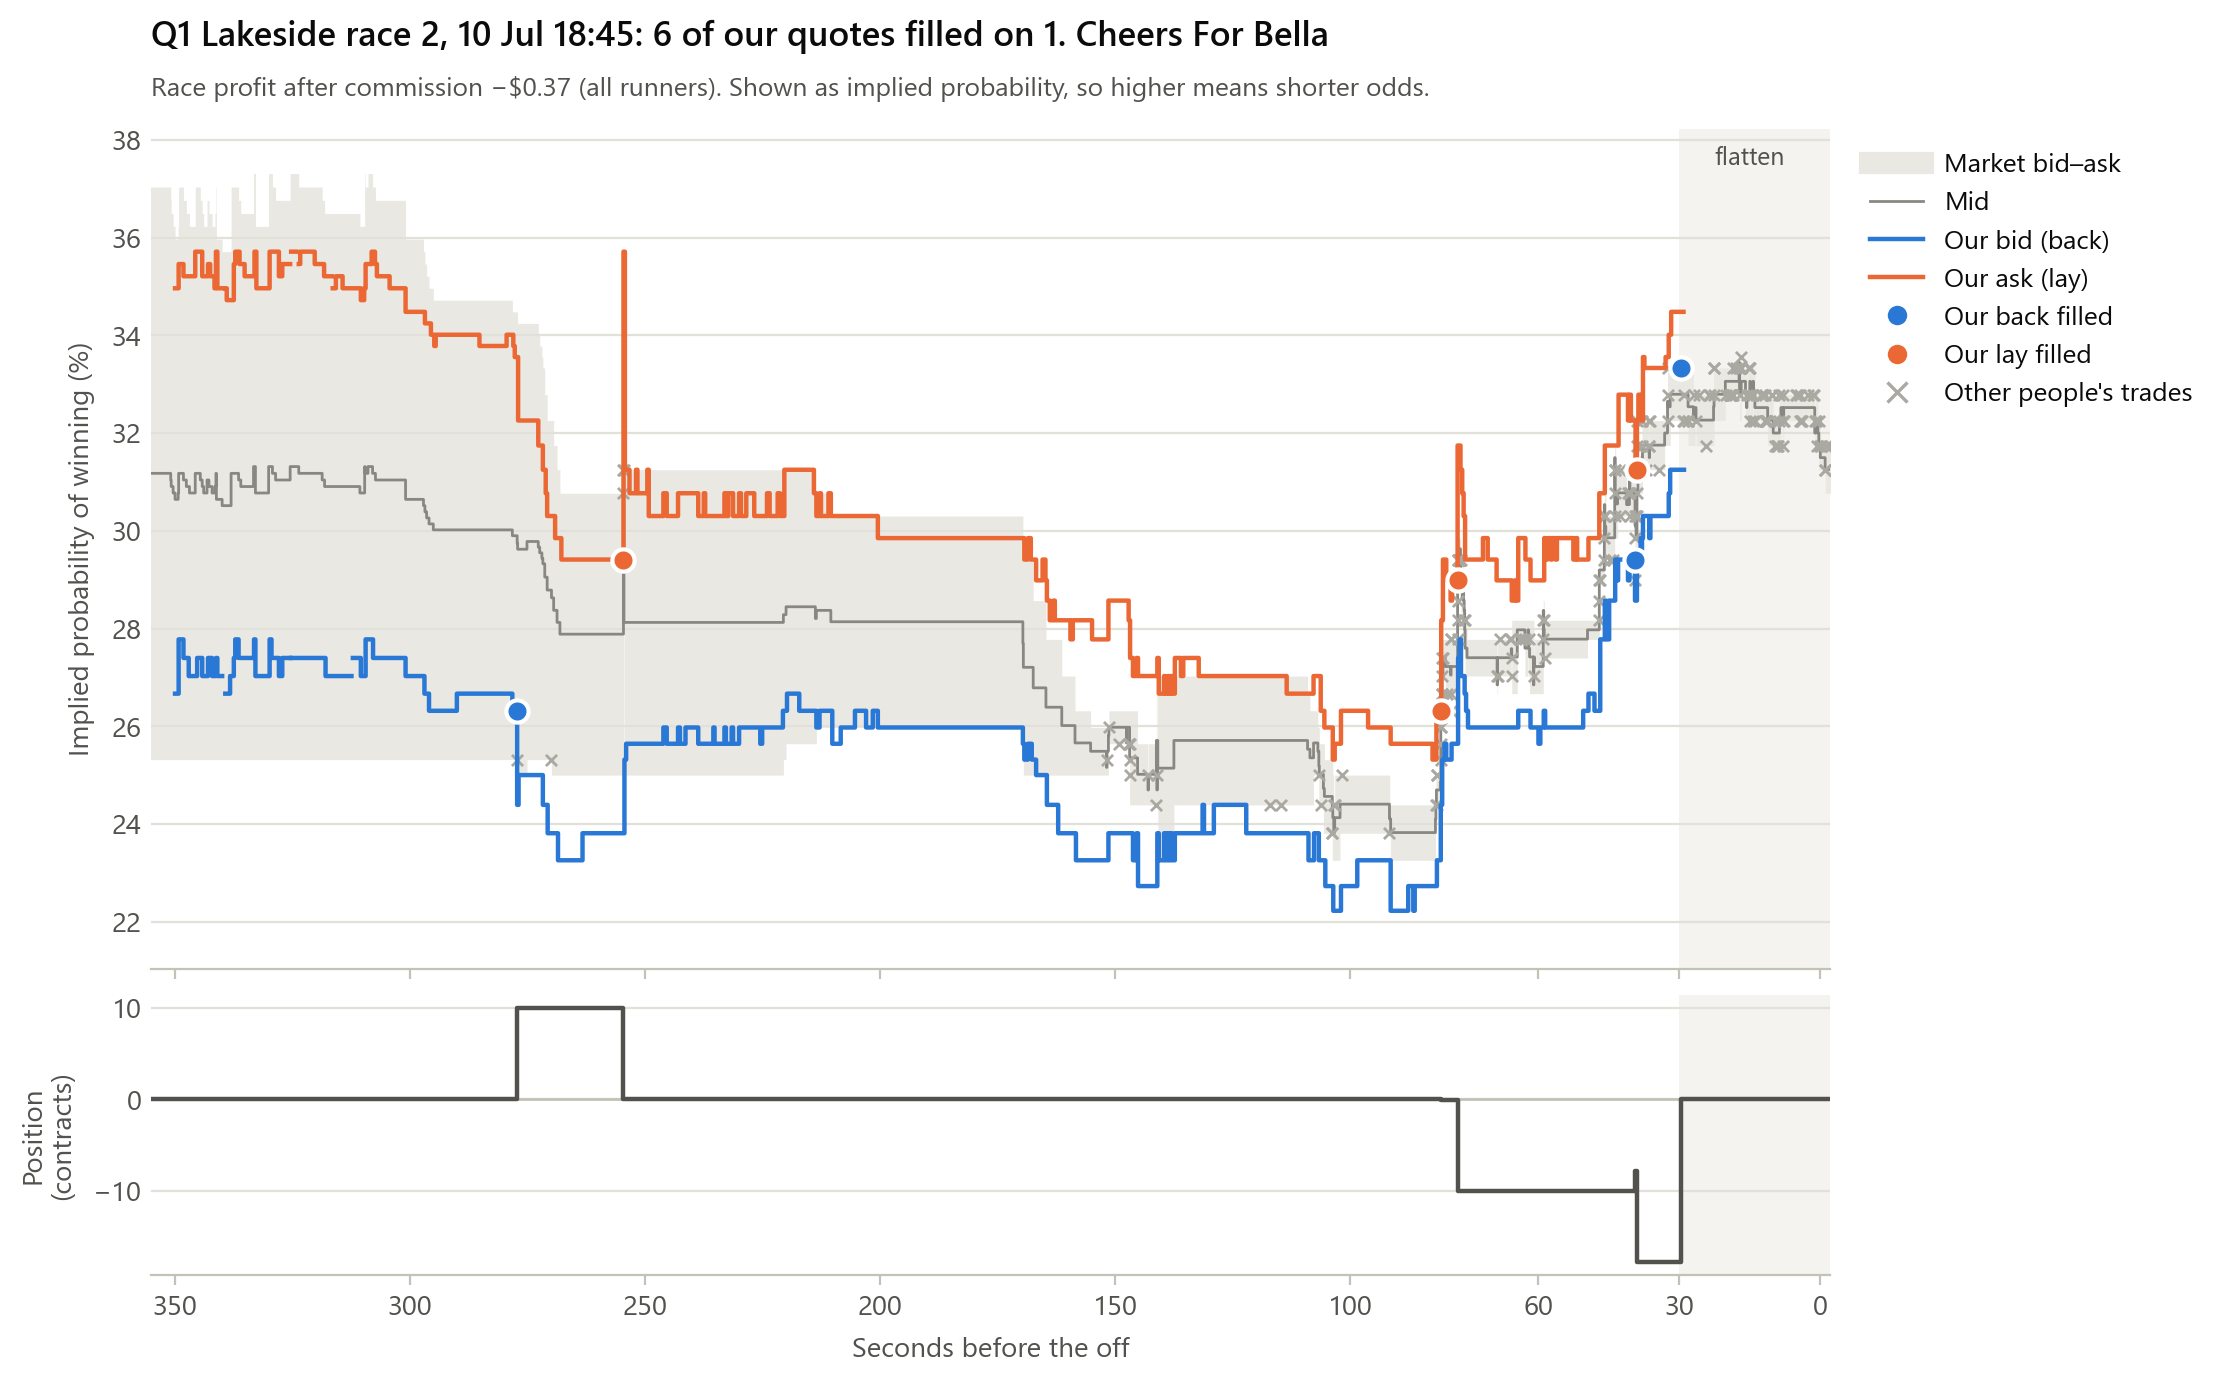

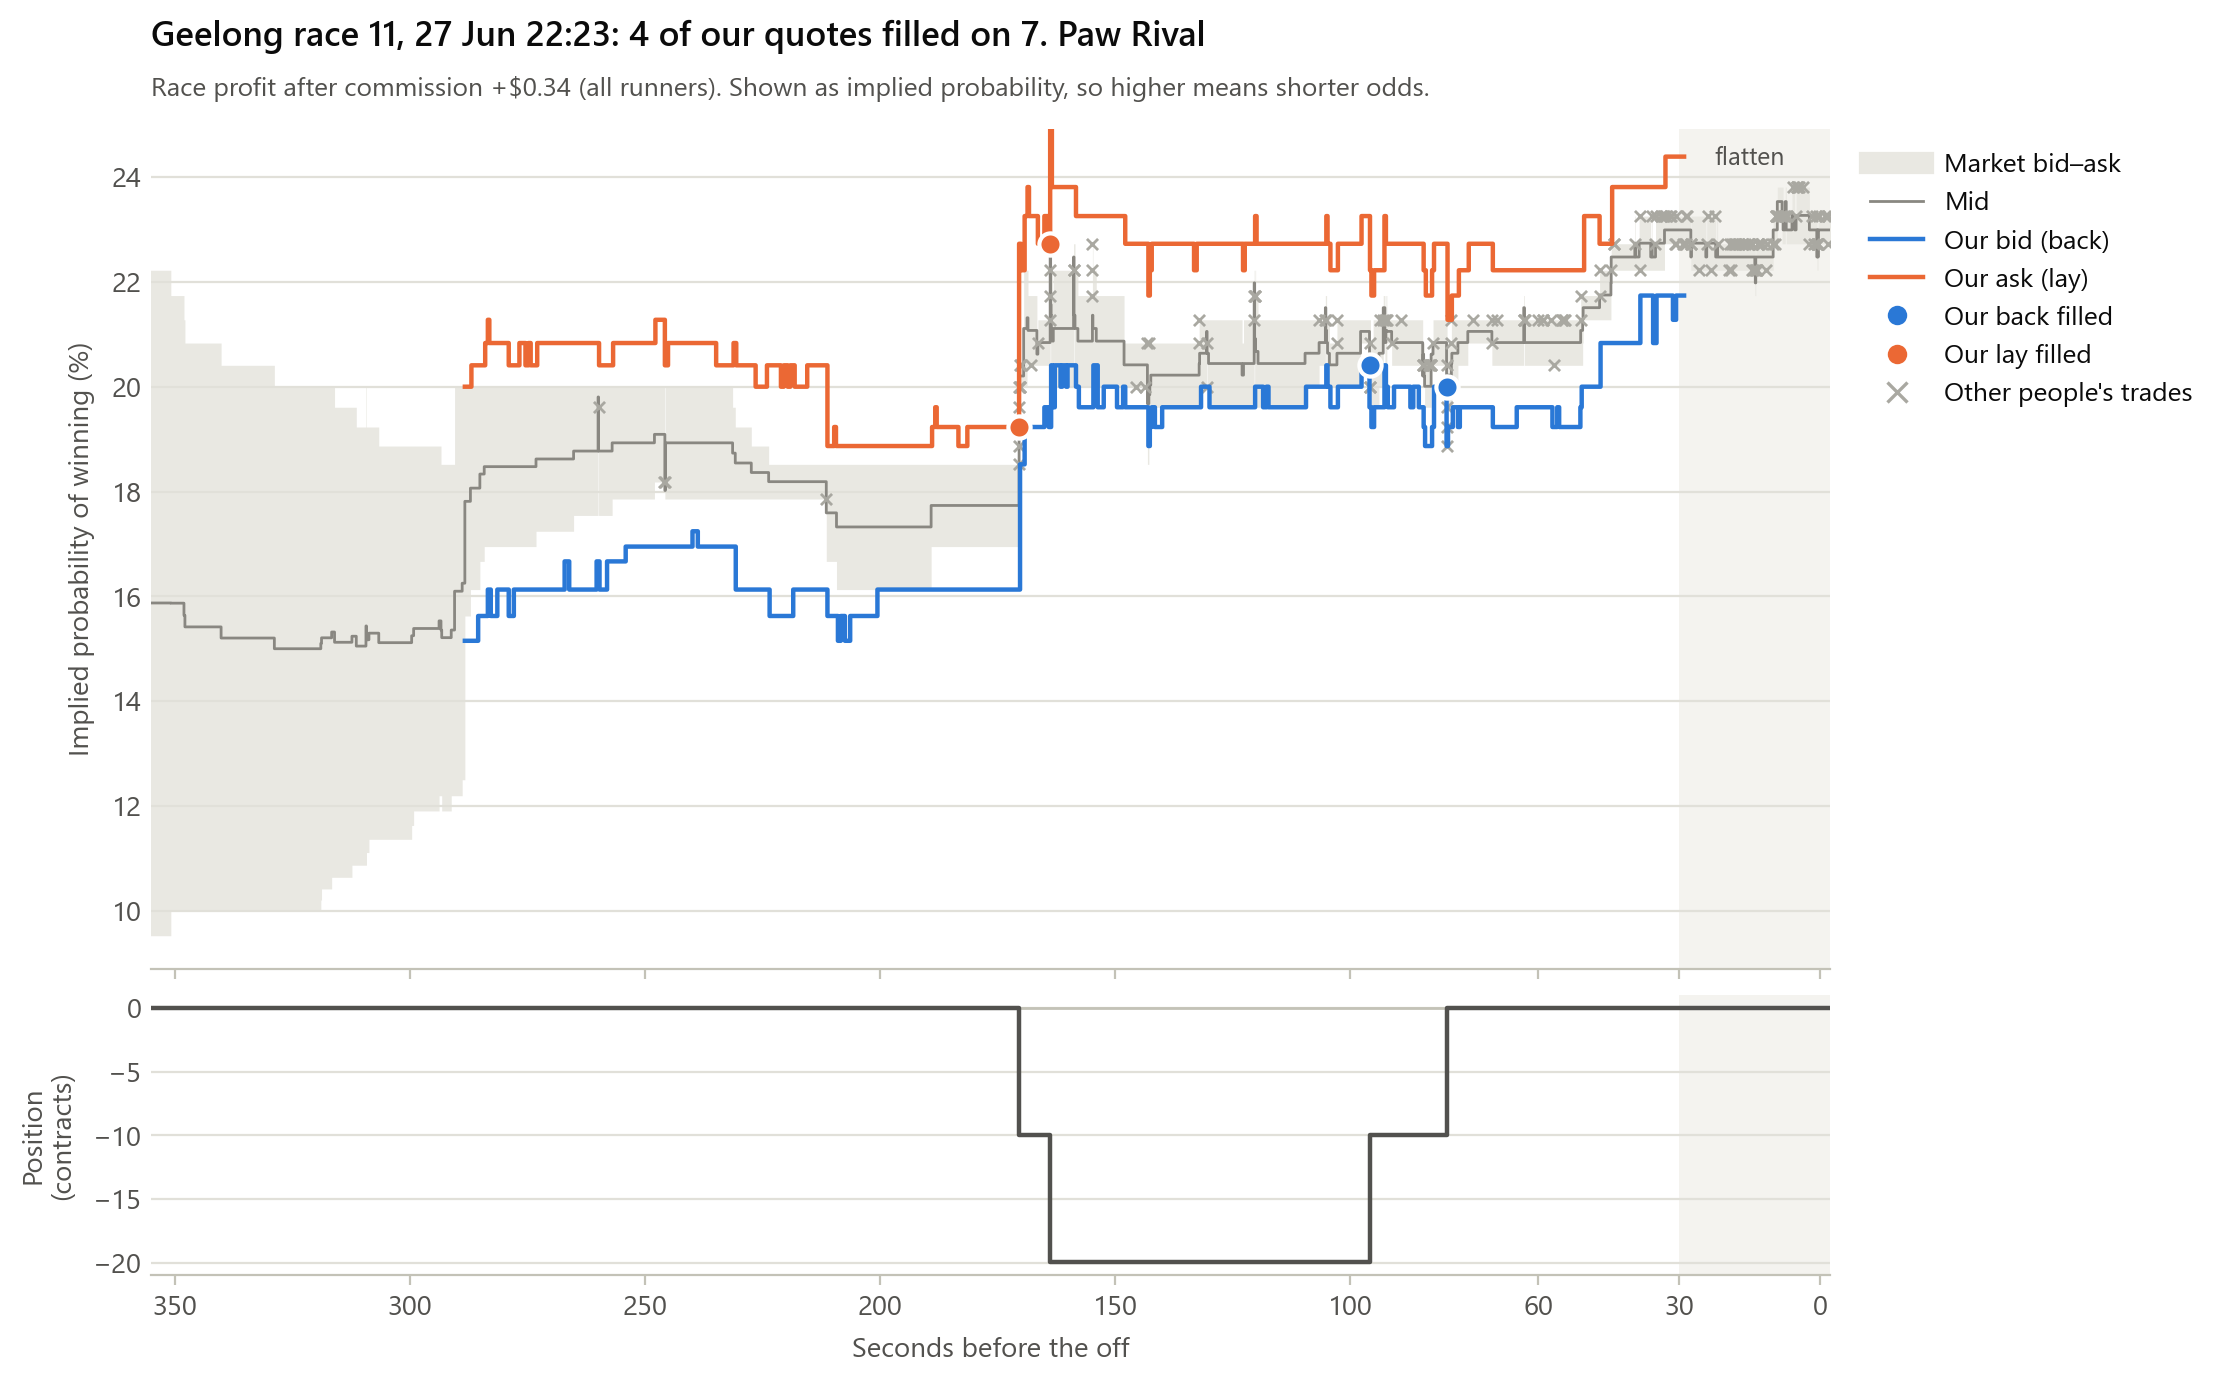

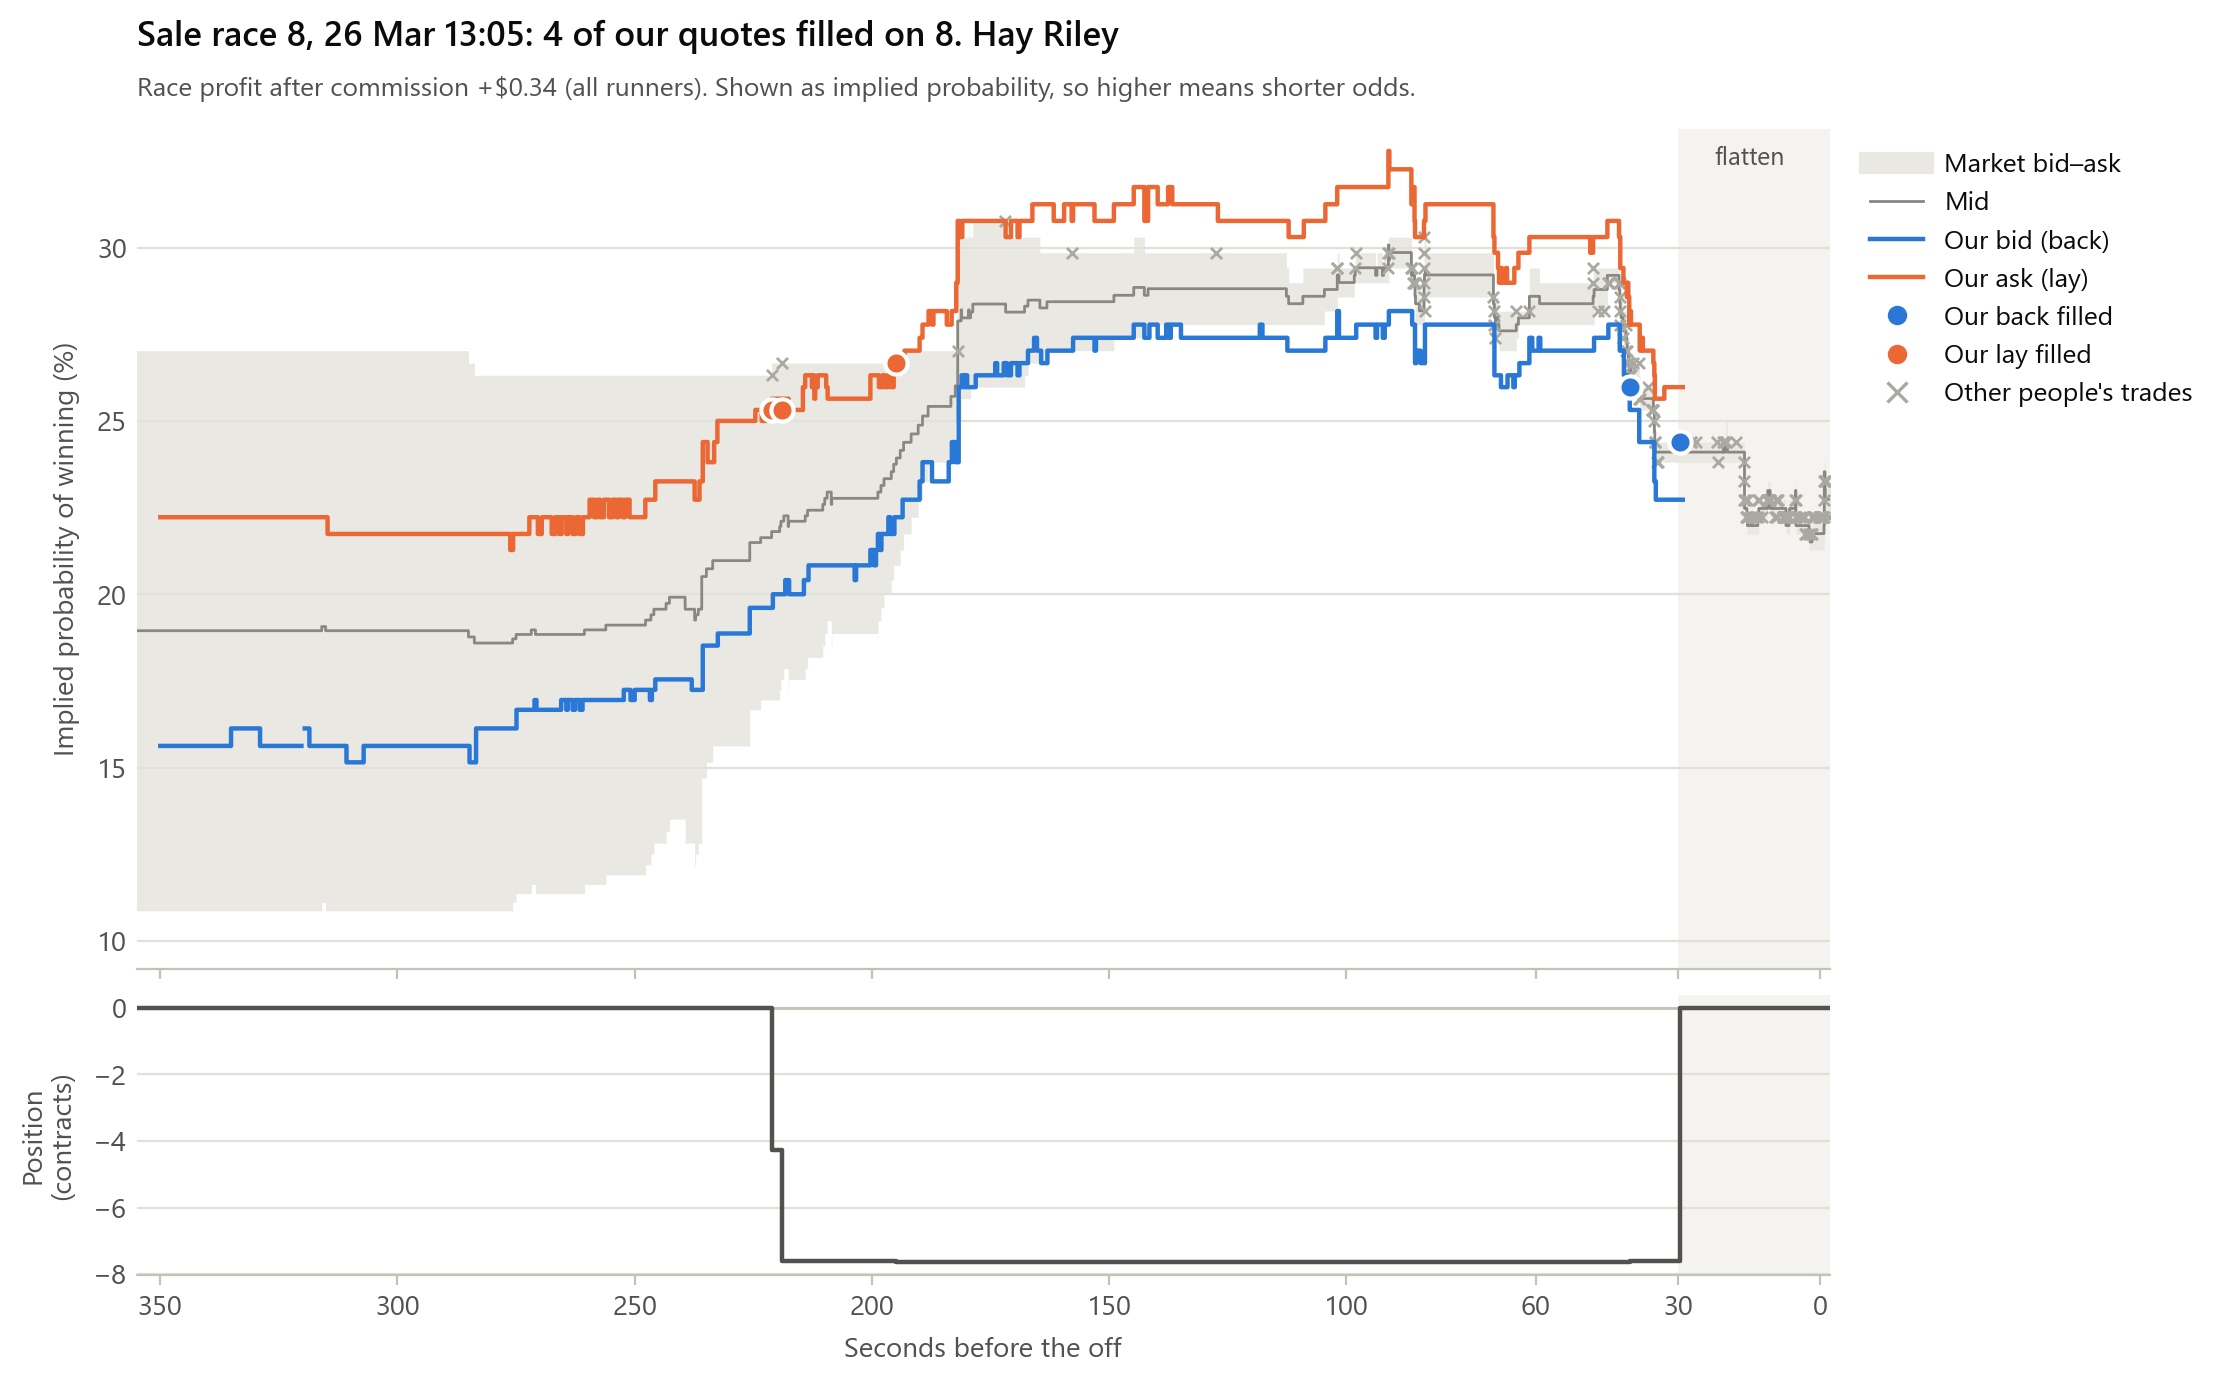

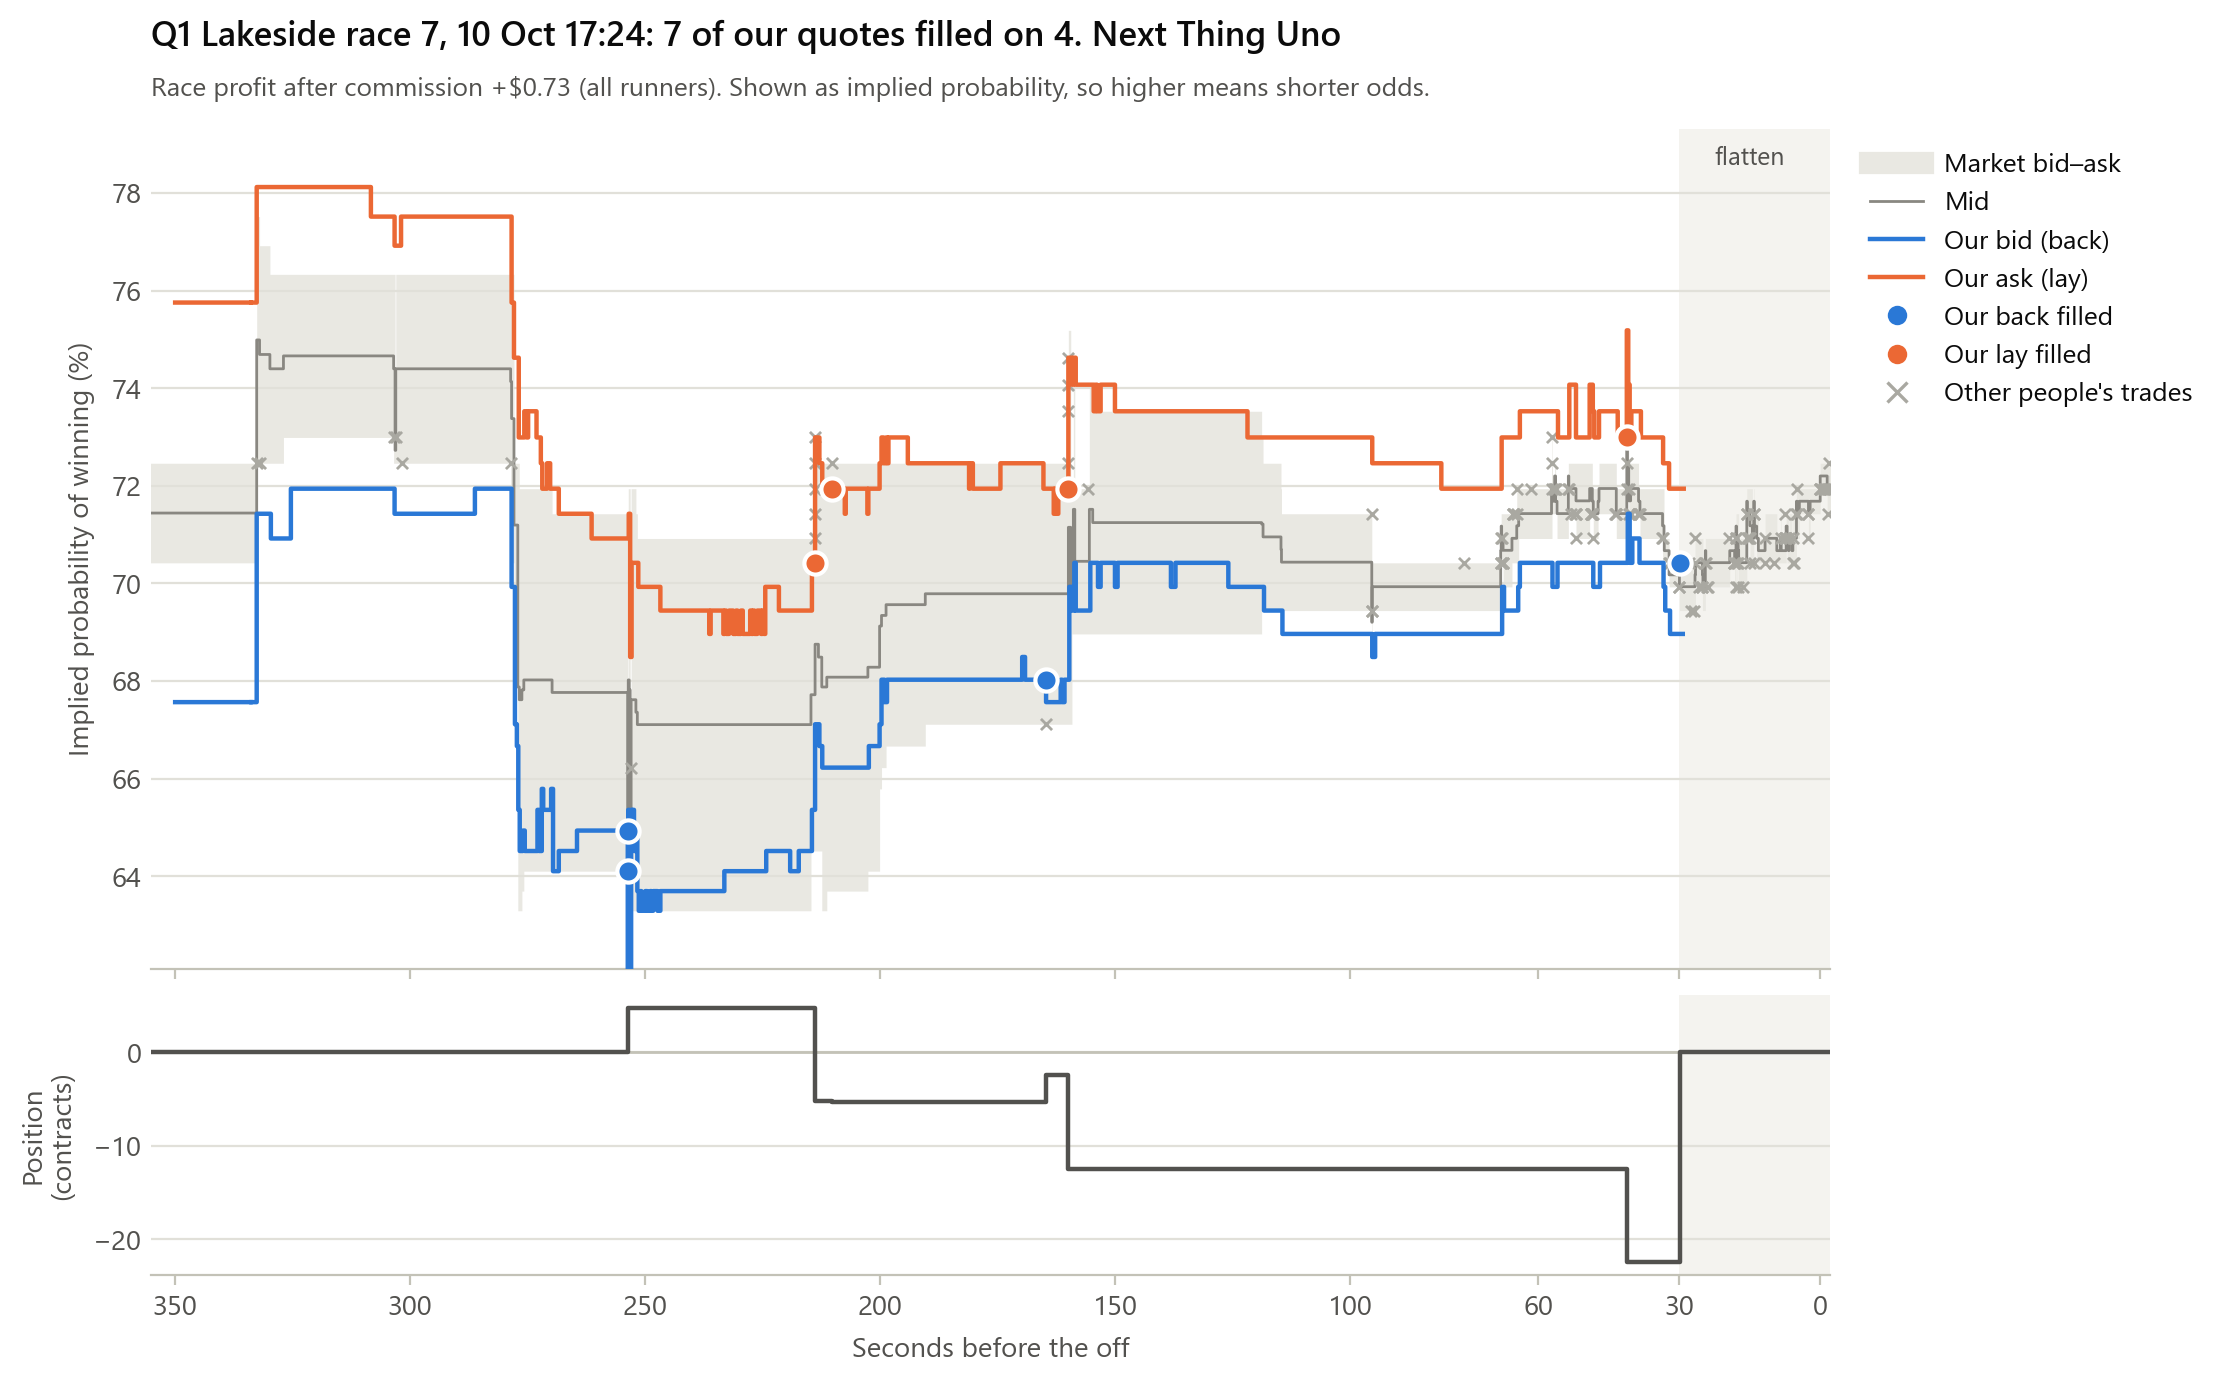

In [4]:
def runner_history(run):
    # The market (bid, ask, mid, other people's trades), our quotes, our fills and our position for one runner,
    # all in seconds before the off, with prices as implied probabilities
    sel, contexts = run["runner"], run["replay"].contexts
    rows, trades = [], []
    for ctx in contexts:
        r = ctx.runner(sel)
        open_book = ctx.status is MarketStatus.OPEN and r.atb and r.atl
        bid, ask = (1 / r.atl[0][0], 1 / r.atb[0][0]) if open_book else (np.nan, np.nan)
        rows.append((ctx.seconds_to_off, bid, ask))
        trades += [(ctx.seconds_to_off, 1 / price) for price, size in r.traded if price > 1 and size > 0]
    book = pd.DataFrame(rows, columns=["t", "bid", "ask"])
    book["mid"] = (book["bid"] + book["ask"]) / 2
    quotes = pd.DataFrame(run["strategy"].quote_log, columns=["t", "sel", "back_odds", "lay_odds"])
    quotes = quotes[quotes["sel"] == sel].assign(bid=lambda q: 1 / q["back_odds"], ask=lambda q: 1 / q["lay_odds"])
    for column in ("bid", "ask"):                 # bridge the brief gap while a quote is cancelled and re-posted
        last_seen = quotes["t"].where(quotes[column].notna()).ffill()
        quotes[column] = quotes[column].ffill().where(last_seen - quotes["t"] <= 1.0)
    off = contexts[-1].market_time
    fills = pd.DataFrame(run["strategy"].fill_log)
    fills = fills[fills["selection_id"] == sel].copy()
    fills["t"] = [(off - t).total_seconds() for t in fills["publish_time"]]
    fills["p"] = 1 / fills["price"]
    return book, pd.DataFrame(trades, columns=["t", "p"]), quotes, fills


def plot_race(run):
    book, trades, quotes, fills = runner_history(run)
    ctx = run["replay"].contexts[-1]
    name = ctx.runner(run["runner"]).selection_name
    profit = run["ledger"].markets[0].net_pnl
    start = pd.Timestamp(ctx.market_time).tz_convert("Australia/Sydney")

    fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 6.8), sharex=True, height_ratios=[3, 1], layout="constrained")
    for ax in (top, bottom):
        ax.axvspan(30, -5, color="#f4f3ef", lw=0, zorder=0)            # after T: no quoting, flatten
    top.fill_between(book["t"], 100 * book["bid"], 100 * book["ask"], step="post", color=SPREAD, lw=0)
    top.step(book["t"], 100 * book["mid"], where="post", color=GREY, lw=1)
    top.scatter(trades["t"], 100 * trades["p"], marker="x", s=16, color="#a9a8a1", lw=1, zorder=3)
    top.step(quotes["t"], 100 * quotes["bid"], where="post", color=BLUE, lw=1.6, zorder=4)
    top.step(quotes["t"], 100 * quotes["ask"], where="post", color=ORANGE, lw=1.6, zorder=4)
    for side, colour in (("BACK", BLUE), ("LAY", ORANGE)):
        ours = fills[fills["side"] == side]
        top.plot(ours["t"], 100 * ours["p"], "o", color=colour, ms=8, zorder=5)
    top.text(15, 0.98, "flatten", transform=top.get_xaxis_transform(), ha="center", va="top", fontsize=9, color=INK_2)
    shown = 100 * np.concatenate([book.loc[book["t"] <= 355, ["bid", "ask"]].to_numpy().ravel(), quotes[["bid", "ask"]].to_numpy().ravel(),
                                  fills["p"].to_numpy()])
    low, high = np.nanpercentile(shown, [0.5, 99.5])        # ignore a momentary spike when setting the scale
    pad = 0.08 * (high - low)
    top.set(ylabel="Implied probability of winning (%)", ylim=(low - pad, high + pad))

    keys = [Line2D([], [], color=SPREAD, lw=8), Line2D([], [], color=GREY, lw=1),
            Line2D([], [], color=BLUE, lw=1.6), Line2D([], [], color=ORANGE, lw=1.6),
            Line2D([], [], marker="o", ls="", color=BLUE, mew=0), Line2D([], [], marker="o", ls="", color=ORANGE, mew=0),
            Line2D([], [], marker="x", ls="", color="#a9a8a1", markeredgecolor="#a9a8a1", mew=1.2)]
    top.legend(keys, ["Market bid–ask", "Mid", "Our bid (back)", "Our ask (lay)", "Our back filled", "Our lay filled",
                      "Other people's trades"], loc="upper left", bbox_to_anchor=(1.01, 1))

    # Our position on this runner: zero until the first fill, then it changes at every fill
    t = np.concatenate([[book["t"].iloc[0]], fills["t"], [book["t"].iloc[-1]]])
    q = np.concatenate([[0.0], fills["q_after"], [fills["q_after"].iloc[-1] if len(fills) else 0.0]])
    bottom.axhline(0, color=LIGHT, lw=1)
    bottom.step(t, q, where="post", color=INK_2, lw=1.6)
    bottom.set(ylabel="Position\n(contracts)", xlabel="Seconds before the off")
    bottom.invert_xaxis()
    bottom.set_xlim(355, max(-2, book["t"].min()))
    bottom.set_xticks([350, 300, 250, 200, 150, 100, 60, 30, 0])

    n_quote = int((fills["tag"] == "quote").sum())
    titles(top, f"{ctx.venue} race {ctx.race_no}, {start:%d %b %H:%M}: {n_quote} of our quotes filled on {name}",
           f"Race profit after commission {'−' if profit < 0 else '+'}${abs(profit):.2f} (all runners). Shown as implied probability, "
           "so higher means shorter odds.")
    plt.show()


for run in chosen:
    plot_race(run)

**What to look for**

- **Our quotes track the market, and close in as the off approaches.** Our bid and ask move with the mid. Five minutes out they sit well away from it, often outside the market's best prices: with so long to go, the A–S risk term is large, and so is the adverse-selection premium (early fills are the most dangerous). Both shrink towards the off, and our quotes move in close to the market's best prices.
- **Fills arrive when the price comes to us.** Most of our fills happen when other people's trades (the crosses) reach our quote: a back fills when someone lays down to our price, a lay when someone backs up to it.
- **Inventory leans the quotes.** After a fill, both of our lines shift so that the trade that would undo the position becomes more likely: after we back a runner, we quote it slightly longer, which makes our lay more likely to fill. That's the A–S reservation price at work, and the position line shows it being worked back towards zero.
- **Gaps in our quotes are deliberate.** We only quote runners priced between 1.2 and 6.0 (a probability of 16.7% to 83%), so when a runner drifts outside that range our quotes disappear until it comes back. A side also goes quiet when one more fill would take our position past the cap of 50 contracts.
- **Everything is flat at the off.** At $T$ we stop quoting and cross the spread to flatten any position of 1 contract or more, so the position line ends at (or very near) zero.